In [32]:
import numpy as np
from matplotlib import pyplot as plt

In [33]:
lambd = 0.05
n = 1000
x = np.random.exponential(lambd, size=n)

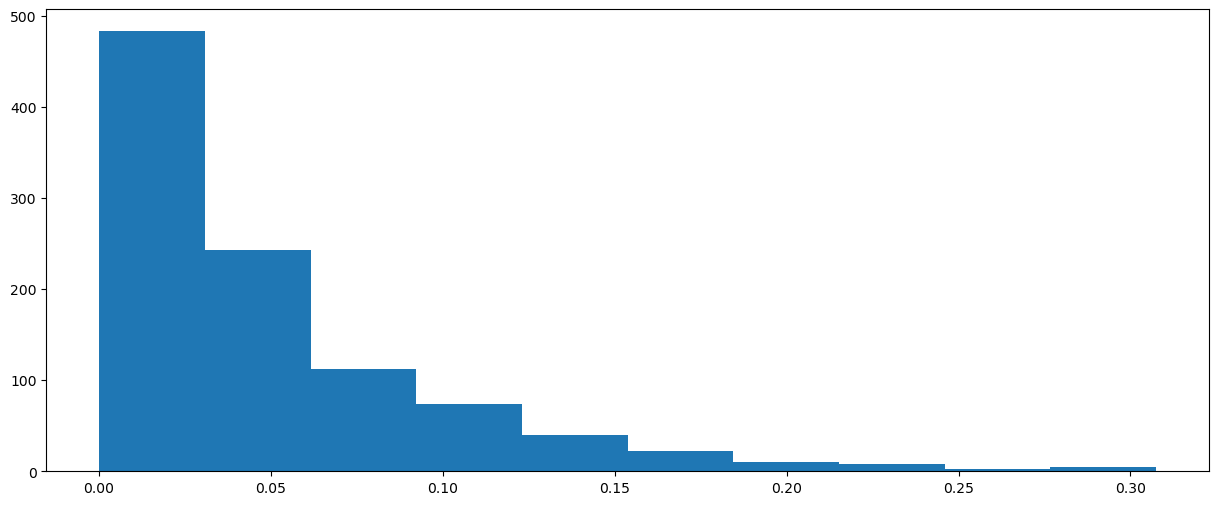

In [34]:
plt.figure(figsize=(15, 6))
_ = plt.hist(x)

# Mean

In [47]:
am = x.mean()

In [48]:
am

np.float64(0.049031061441172315)

In [49]:
x.prod() ** (1 / n), x.min()

(np.float64(0.0), np.float64(6.722588127730793e-05))

In [50]:
gm = np.exp(np.log(x).mean())

In [51]:
gm

np.float64(0.027100975446254845)

In [53]:
hm = n / ((1 / x).sum())

In [54]:
hm

np.float64(0.007705445208264782)

In [70]:
ams = []
gms = []
hms = []
meds = []
meds_ln05 = []

t = range(100, 10001, 100)
for n in t:
    lambd = 0.05
    x = np.random.exponential(lambd, size=n)

    ams.append(x.mean())
    gms.append(np.exp(np.log(x).mean()))
    hms.append(n / ((1 / x).sum()))
    meds.append(np.median(x))
    
    meds_ln05.append(-np.median(x) / np.log(0.5))
    # meds.append(np.quantile(x, 50))
    # meds.append(np.percentile(x, 0.50))
    
    

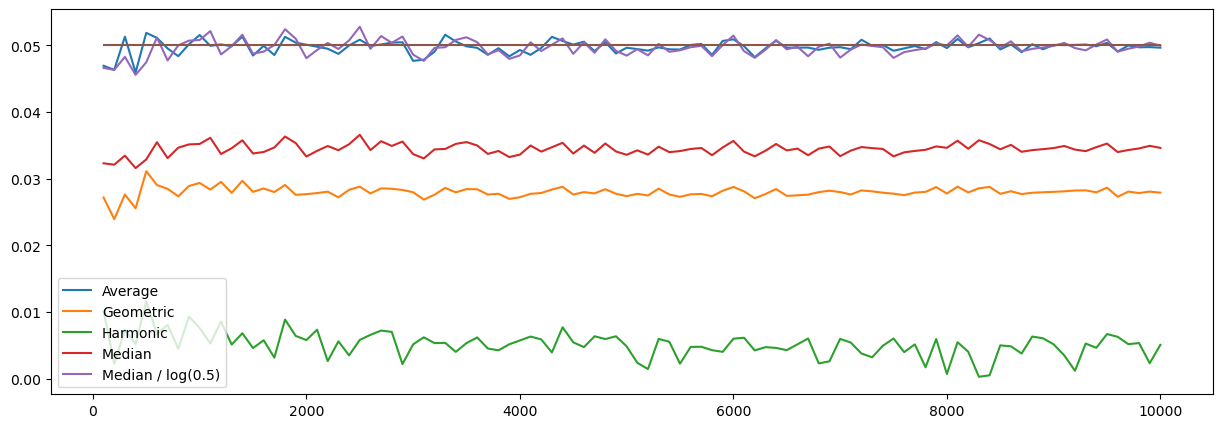

In [71]:
plt.figure(figsize=(15, 5))
plt.plot(t, ams, label='Average')
plt.plot(t, gms, label='Geometric')
plt.plot(t, hms, label='Harmonic')
plt.plot(t, meds, label='Median')
plt.plot(t, meds_ln05, label='Median / log(0.5)')
plt.plot(t, [lambd] * len(t))
plt.legend()



In [72]:
#

In [76]:
import scipy

x0 = 0

n = 1000
x = scipy.stats.cauchy(loc=x0).rvs(n)

In [77]:
x.mean()

np.float64(1.360430451003386)

In [78]:
np.exp(np.log(x).mean())

C:\Users\v.miroshnychenko\AppData\Local\Temp\ipykernel_23588\3300707545.py:1: RuntimeWarning: invalid value encountered in log
  np.exp(np.log(x).mean())


np.float64(nan)

In [80]:
n / (1 / x).sum()

np.float64(0.07781721251424709)

In [81]:
np.median(x)

np.float64(0.06926955316286562)

In [83]:
x.min(), x.max()

(np.float64(-100.69428385807709), np.float64(668.6441383499755))

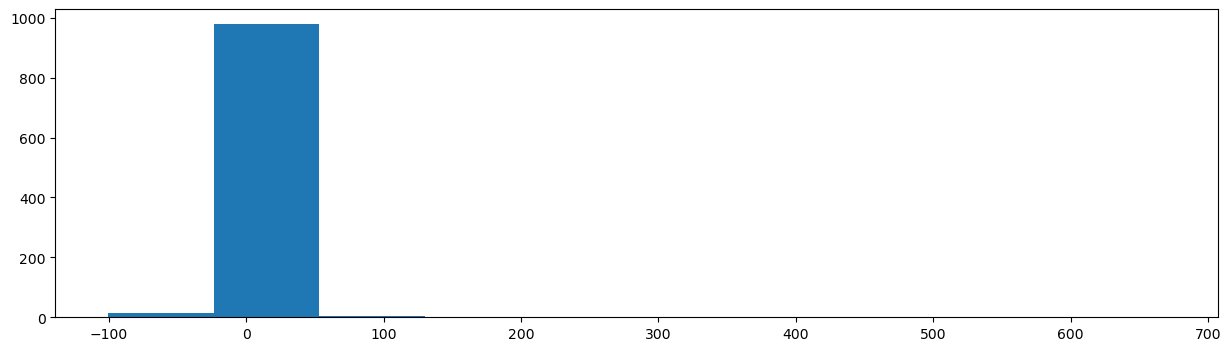

In [85]:
plt.figure(figsize=(15, 4))
_ = plt.hist(x)

In [91]:
ams = []
gms = []
hms = []
meds = []
# meds_ln05 = []

t = range(100, 10001, 100)
for n in t:
    x = scipy.stats.cauchy(loc=x0).rvs(n)

    ams.append(x.mean())
    # gms.append(np.exp(np.log(x).mean()))
    hms.append(n / ((1 / x).sum()))
    meds.append(np.median(x))
    
    # meds_ln05.append(-np.median(x) / np.log(0.5))
    # meds.append(np.quantile(x, 50))
    # meds.append(np.percentile(x, 0.50))
    
    

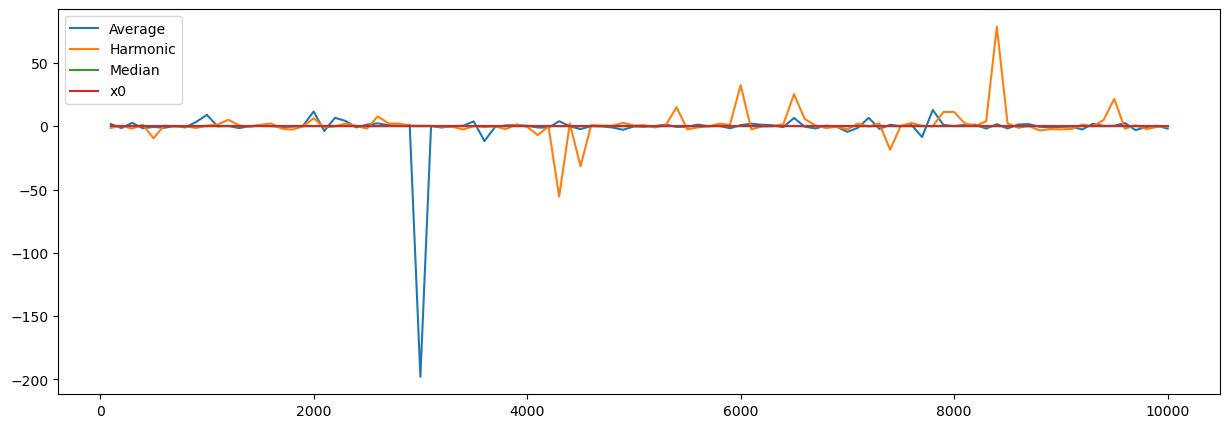

In [92]:
plt.figure(figsize=(15, 5))
plt.plot(t, ams, label='Average')
# plt.plot(t, gms, label='Geometric')
plt.plot(t, hms, label='Harmonic')
plt.plot(t, meds, label='Median')
# plt.plot(t, meds_ln05, label='Median / log(0.5)')
plt.plot(t, [x0] * len(t), label='x0')
plt.legend()



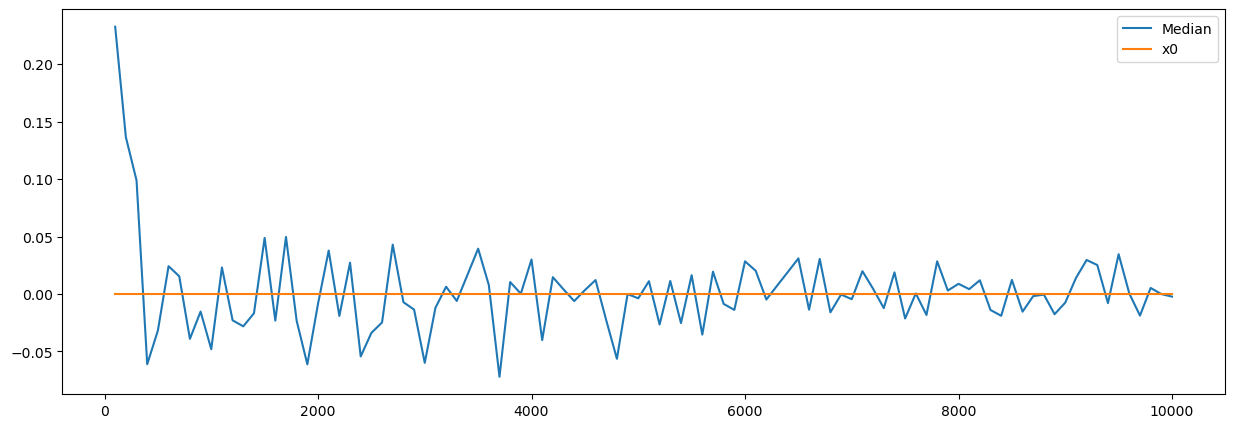

In [96]:
plt.figure(figsize=(15, 5))
# plt.plot(t, ams, label='Average')
# plt.plot(t, hms, label='Harmonic')
plt.plot(t, meds, label='Median')
plt.plot(t, [x0] * len(t), label='x0')
plt.legend()



# Scale estimation

In [135]:
import scipy

x0 = 0

n = 1000
x = scipy.stats.cauchy(loc=x0).rvs(n)
# x = np.random.normal(0, 1, size=n)

In [136]:
def sigma2(x):
    return ((x - x.mean()) ** 2).mean()

def std(x):
    return ((x - x.mean()) ** 2).sum() / (len(x) - 1)

In [137]:
sigma2(x)

np.float64(1054.9396865575388)

In [138]:
std(x)

np.float64(1055.9956822397785)

In [139]:
x.max() - x.min()

np.float64(1282.3436526822125)

In [149]:
def mad_mean(x):
    # print(x.mean())
    return np.abs(x - x.mean()).mean()

In [150]:
mad_mean(x)

np.float64(31.4535302214453)

In [151]:
def mad_median(x):
    # print(np.median(x))
    return np.abs(x - np.median(x)).mean()

In [152]:
mad_median(x)

np.float64(19.563319893976864)

In [153]:
q1, q3 = np.percentile(x, [25, 75])
q3 - q1

np.float64(2.032092806626915)

In [154]:
(q3 - q1) / 2

np.float64(1.0160464033134575)

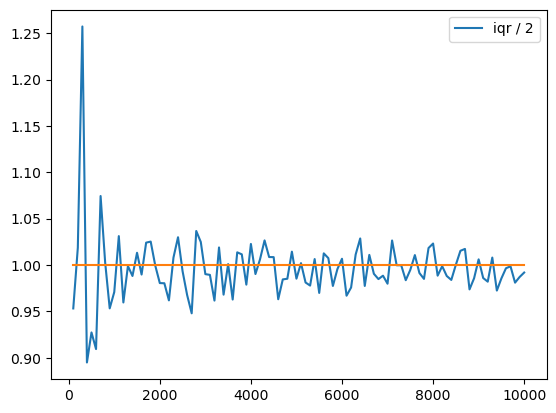

In [157]:
iqr2s = []
exs = []
t = range(100, 10001, 100)
for n in t:
    x = scipy.stats.cauchy(loc=x0).rvs(n)

    q1, q3 = np.percentile(x, [25, 75])
    iqr2s.append((q3 - q1) / 2)

    exs.append(mad_mean(x))
    
plt.plot(t, iqr2s, label='iqr / 2')
# plt.plot(t, exs, label='example')
plt.plot(t, [1] * len(t))    
plt.legend()


# whiskerplot

In [184]:
n = 100
x = np.random.normal(0, 1, size=n)
y = np.random.exponential(1, size=n)
z = scipy.stats.cauchy().rvs(n)
# y = np.random.exponential(0.01, size=n)


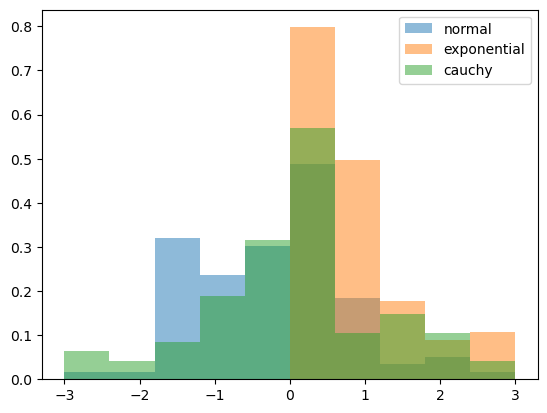

In [187]:
plt.hist(x, alpha=0.5, label='normal', density=True, range=(-3, 3))
plt.hist(y, alpha=0.5, label='exponential', density=True, range=(-3, 3))
plt.hist(z, alpha=0.5, label='cauchy', density=True, range=(-3, 3))

plt.legend()

(-10.0, 10.0)

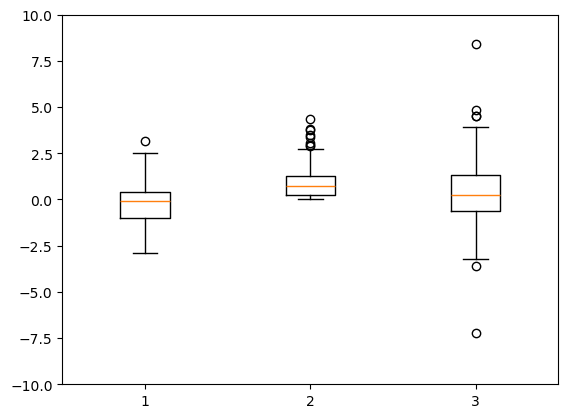

In [190]:
_ = plt.boxplot([x, y, z])
plt.ylim(-10, 10)

In [ ]:
#      Q1-1.5IQR   Q1   median  Q3   Q3+1.5IQR
#                   |-----:-----|
#   o      |--------|     :     |--------|    o  o
#                   |-----:-----|
# flier             <----------->            fliers